# Fitting Patient Parameters in Log Space

In [1]:
import os
import re
import sys
import pickle
import numpy as np
import pandas as pd
import scipy as sc
from scipy.stats import spearmanr, kendalltau
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb
from matplotlib import colormaps
from lmfit import minimize, Parameters
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import test_progression, TruncateDataframe, ExtractTreatmentFromDf, LoadPatientData, calc_critical_treatment_threshold, GetPatientIDs, calc_delta_benefit
from fittingUtils import residual, compute_r_sq, load_fit, generate_fitSummaryDf
from plotUtils import PlotDrug, PlotData, convert_to_rgb_grayscale, redistribute_rgb
from odeModels import LotkaVolterraModel

In [2]:
file_path = os.path.dirname(os.path.abspath("__file__"))
out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Prog_fits")

RERUN_FITTING = True

In [3]:
def SimulateFit(fit_params, dataDf, dt=1, solver_kws={}):
    myModel = LotkaVolterraModel()
    myModel.SetParams(**fit_params)
    myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(dataDf),**solver_kws)
    # Interpolate to the desired time grid
    t_eval = np.arange(0, myModel.resultsDf.Time.max(), dt)
    trimmedResultsDic = {'Time': t_eval}
    for variable in ['S', 'R', 'TumourSize', 'DrugConcentration']:
        f = sc.interpolate.interp1d(myModel.resultsDf.Time, myModel.resultsDf[variable])
        trimmedResultsDic = {**trimmedResultsDic, variable: f(t_eval)}
    myModel.resultsDf = pd.DataFrame(trimmedResultsDic)
    return myModel

In [4]:
def Plot_method(df, legend=False, drug_label="Drug Concentration",
         ax=None, linewidth=5, drug_color = 'k', colors = None, **kwargs):
    if ax is None: fig, ax = plt.subplots(1, 1)
    linestyles = ['-', (0, (10,10)), (0, (5,5))]
    for i, var in enumerate(["TumourSize", 'S', 'R']):
        ax.plot(df['Time'], df[var], linewidth=linewidth, linestyle=linestyles[i], color=colors[var], **kwargs)

    PlotDrug(df, ax, drug_color, plotDrugAsBar = True, currDrugBarPosition = 1.25)

    # Format the plot
    ax.set_title(kwargs.get('title', ''))
    ax.yaxis.get_major_ticks()[-1].set_visible(False); ax.tick_params(right = False, top = False)

## Patient Datasets

Loaded Patient IDs: [1, 2, 3, 4, 6, 11, 12, 13, 14, 15, 16, 17, 19, 20, 22, 24, 25, 26, 28, 29, 30, 31, 32, 36, 37, 39, 40, 41, 42, 44, 46, 50, 51, 52, 54, 55, 56, 58, 60, 61, 62, 63, 64, 66, 71, 75, 77, 78, 79, 81, 83, 84, 85, 86, 87, 88, 91, 92, 93, 94, 95, 96, 97, 99, 100, 101, 102, 104, 105, 106, 108, 109]


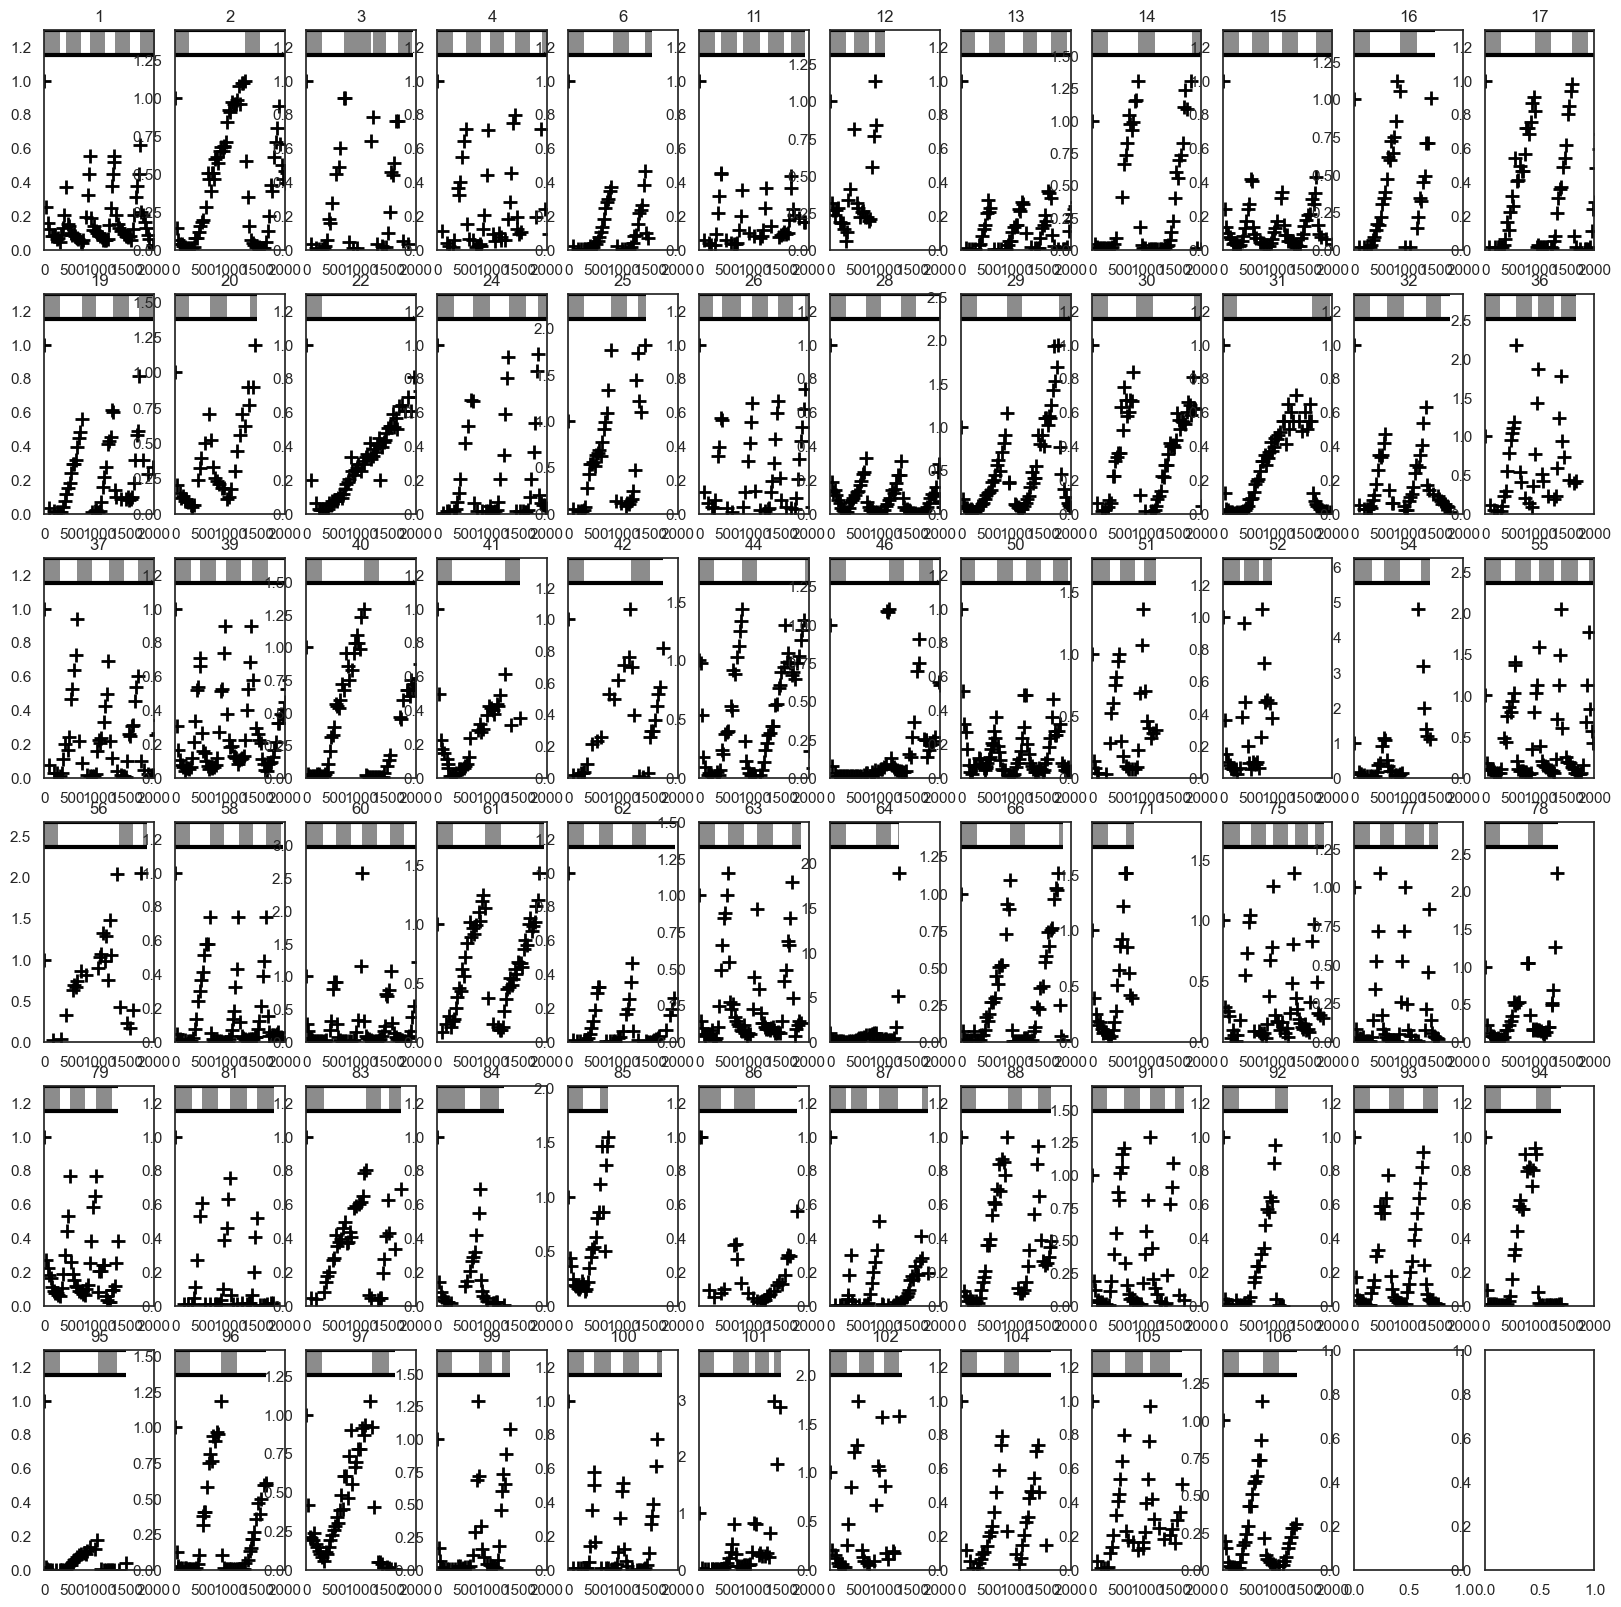

In [5]:
data_path = "../patients/Bruchovsky_et_al/Complete_data"
patientIds = GetPatientIDs(data_path)
print("Loaded Patient IDs: " + str(patientIds))
patientIds = patientIds[:-2]  # Exclude two trickiest patients

plt.rcParams['font.size'] = '18'
fig, axs = plt.subplots(6, int((len(patientIds)+5)/6), figsize=(20, 20))
for i, patientId in enumerate(patientIds):
    dataDf = LoadPatientData(patientId, data_path)
    PlotData(dataDf, axs.flatten()[i], drugBarPosition=max(dataDf.PSA)*1.15,
             drugBarHeight=max(dataDf.PSA)*0.15)
    axs.flatten()[i].set_title(patientId)
    axs.flatten()[i].set_ylim(0, max(dataDf.PSA) * 1.3)
if len(patientIds) % 2 == 1: axs.flatten()[-1].axis('off');

In [6]:
n = len(patientIds)
cols = [colormaps['tab10'](i/n) for i in range(n)]
markers = ['v', 's', 'X', 'P', 'o', '*', 'd',]

## Fit to first cycle only

These parameter values can then subsequently be used for validation later.

In [7]:
out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Trunc_fits_log_space_all")

patientsToAnalyseList = patientIds
solver_kws={'method':'RK45', 'absErr':1.0e-10, 'relErr':1.0e-10,
            'suppressOutputB':False}
optimiser_kws = {'method':'least_squares', 'xtol':1e-8, 'ftol':1e-8,
                 'max_nfev':200,'nan_policy':'omit', 'verbose':0}
my_residual_kws = {'log_transform': True}

# Model Parameters
model_name = "LotkaVolterraModel"; params = Parameters()
working_dir = os.path.join(out_dir, model_name)

# New
params.add('turnover', min=0.01, max=1., vary=True)
params.add('K', value=3, min=2.5, max=5, vary=True)

# Fixed from historical data/estimates
params.add('fR', value=1e-5, vary=False)
params.add('cost', value=0.1, vary=False)
params.add('rS', value=0.027, vary=False)
params.add('n0', value=0.1, vary=False)  # Will be matched to initial value

# Fixed/Calculated Parameters
params.add('rR', expr='(1-cost)*rS', vary=False)
params.add('dS', expr='turnover*rS', vary=False); params.add('dR', expr='dS', vary=False)
params.add('dD', value=1.5, vary=False); params.add('theta', value=1, vary=False)
params.add('D', value=1, vary=False); params.add('DMax', value=1, vary=False)
params.add('S0', expr='n0*(1-fR)', vary=False); params.add('R0', expr='n0*fR', vary=False)

In [8]:
if RERUN_FITTING:
    for patientId in tqdm(patientsToAnalyseList):
        # Load data
        training_data_df = LoadPatientData(patientId, data_path)
        training_data_df = training_data_df.dropna(subset=['PSA']).reset_index()

        last_cycle1_index = training_data_df[training_data_df['CycleId'] == 1].index[-1]
        
        training_data_df = training_data_df[:last_cycle1_index+2]
        
        # Setup env
        curr_out_dir = os.path.join(working_dir,"patient%d"%patientId)
        os.makedirs(curr_out_dir, exist_ok=True)
        tmp_model = LotkaVolterraModel()
        curr_params = Parameters()
        curr_params.add_many(*[params[x] for x in params.keys()])

        # Set up initial conditions
        if params['n0'].vary==False: curr_params['n0'].value = training_data_df.PSA.iloc[0]

        # Fit
        tmp_model.SetParams(**params)
        fit_obj = minimize(residual, params, args=(training_data_df, tmp_model, 
                                                        "PSA", solver_kws, my_residual_kws), **optimiser_kws)
        fit_obj.fitId = 0
        fit_obj.numericalStabilisation = tmp_model.numericalStabilisationB
        fit_obj.modelName = model_name
        fit_obj.data = training_data_df
        fit_obj.rSq = compute_r_sq(fit_obj, training_data_df, feature="PSA")

        # Post-process
        pickle.dump(obj=fit_obj, file=open(os.path.join(curr_out_dir,
                                                        "fitObj_fit_%d.p"%(fit_obj.fitId)), "wb"))

  0%|          | 0/70 [00:00<?, ?it/s]

100%|██████████| 70/70 [00:57<00:00,  1.21it/s]


In [9]:
# Store patient parameters in a dataframe
if RERUN_FITTING:
    trunc_df = pd.DataFrame()
    for patient_dir in os.listdir(os.path.join(out_dir, model_name)):
        fitSummaryDf = generate_fitSummaryDf(os.path.join(out_dir, model_name, patient_dir))
        fitSummaryDf.insert(0, "PatientId",  int(re.findall(r'\d+', patient_dir)[0]))
        trunc_df = pd.concat([trunc_df, fitSummaryDf], axis=0)
        
    trunc_df['TimeInTrial'] = trunc_df['PatientId'].apply(lambda x: \
        LoadPatientData(x, data_path).Time.max())
    trunc_df = trunc_df.sort_values(by="PatientId").reset_index()
    trunc_df = trunc_df[trunc_df['PatientId'].isin(patientIds)]
    trunc_df['Cost'] = 1 - trunc_df['rR'] / trunc_df['rS']; 
    trunc_df['Turnover'] = trunc_df['dS'] / trunc_df['rS']
    trunc_df['K'] = 2.5

    #Test progression
    trunc_df['Progression'] = trunc_df.apply(lambda x: test_progression(x.to_dict()), axis=1)
    print("Progression: %d/%d"%(trunc_df.Progression.sum(), len(trunc_df)), end='')
    print(f"  ({[x for x in trunc_df.PatientId[trunc_df.Progression==True]]})")

    # Save patient params
    trunc_df.to_csv("patient_fits/first_cycle_params_log_space.csv", index=False)
else:
    trunc_df = pd.read_csv("patient_fits/first_cycle_params_log_space.csv")

Progression: 66/70  ([1, 2, 3, 4, 6, 11, 12, 13, 14, 15, 16, 17, 19, 20, 22, 24, 25, 26, 28, 29, 30, 32, 36, 37, 39, 40, 41, 42, 44, 50, 51, 52, 54, 55, 56, 58, 60, 61, 62, 63, 64, 66, 71, 75, 77, 78, 79, 81, 83, 84, 85, 86, 87, 88, 91, 92, 93, 94, 96, 97, 100, 101, 102, 104, 105, 106])


## Parameter Value Comparison


In [11]:
linear_params = pd.read_csv("patient_fits/first_cycle_params_all.csv")
log_params = trunc_df

In [12]:
def simulate_doubling_time(params):
    model = LotkaVolterraModel()
    model.SetParams(**params)
    model.Simulate([[0, 2000, 0]])
    model.resultsDf = model.resultsDf[model.resultsDf.TumourSize < params['n0']*1.2]
    # plt.plot(model.resultsDf.Time, model.resultsDf.TumourSize)
    
    return model.resultsDf.Time.max()

In [43]:
# Generate a table with patient id, predicted doubling time, and true doubling time
doubling_time_data = []

for patientId in patientIds:
    param_sets = [linear_params.loc[linear_params.PatientId == patientId].iloc[0].to_dict(),
                  log_params.loc[log_params.PatientId == patientId].iloc[0].to_dict()]
    doubling_times = [simulate_doubling_time(param_set) for param_set in param_sets]
    doubling_time_data.append([patientId, doubling_times[0], doubling_times[1]])

doubling_time_df = pd.DataFrame(doubling_time_data, columns=['PatientId', 'Linear Space', 'Log Space'])
print(doubling_time_df)

    PatientId  Linear Space  Log Space
0           1        15.174     12.660
1           2      2000.000     39.551
2           3        29.727     21.089
3           4        17.015     14.818
4           6      2000.000     59.733
..        ...           ...        ...
65        101        35.453     32.213
66        102        14.583     12.272
67        104        53.849     21.446
68        105        20.479     14.195
69        106        36.096     19.840

[70 rows x 3 columns]


In [44]:
# 1. Spearman's Rank Correlation
rho, p_spearman = spearmanr(doubling_time_df['Linear Space'], doubling_time_df['Log Space'])

# 2. Kendall's Tau Correlation
tau, p_kendall = kendalltau(doubling_time_df['Linear Space'], doubling_time_df['Log Space'])

# --- Print Results ---
print("--- Robustness of Biomarker Rankings ---")
print(f"Sample Size (N) = {len(doubling_time_df)}")
print(f"Spearman's rho : {rho:.3f} (P = {p_spearman:.4f})")
print(f"Kendall's tau  : {tau:.3f} (P = {p_kendall:.4f})")

--- Robustness of Biomarker Rankings ---
Sample Size (N) = 70
Spearman's rho : 0.788 (P = 0.0000)
Kendall's tau  : 0.599 (P = 0.0000)


In [14]:
def calc_AT_score(patientId, **kwargs):
    params = kwargs
    return calc_delta_benefit(kappa=0.2, **params)

In [42]:
# Generate a table with patient id, predicted doubling time, and true doubling time
at_score_list = []

for patientId in patientIds:
    param_sets = [linear_params.loc[linear_params.PatientId == patientId].iloc[0].to_dict(),
                  log_params.loc[log_params.PatientId == patientId].iloc[0].to_dict()]
    at_scores = [calc_AT_score(patientId, **param_set) for param_set in param_sets]
    at_score_list.append([patientId, at_scores[0], at_scores[1]])

at_score_df = pd.DataFrame(at_score_list, columns=['PatientId', 'Linear Space', 'Log Space'])

In [22]:
# 1. Spearman's Rank Correlation
rho, p_spearman = spearmanr(at_score_df['Linear Space'], at_score_df['Log Space'])

# 2. Kendall's Tau Correlation
tau, p_kendall = kendalltau(at_score_df['Linear Space'], at_score_df['Log Space'])

# --- Print Results ---
print("--- Robustness of Biomarker Rankings ---")
print(f"Sample Size (N) = {len(at_score_df)}")
print(f"Spearman's rho : {rho:.3f} (P = {p_spearman:.4e})")
print(f"Kendall's tau  : {tau:.3f} (P = {p_kendall:.4e})")

--- Robustness of Biomarker Rankings ---
Sample Size (N) = 70
Spearman's rho : 0.719 (P = 2.4273e-12)
Kendall's tau  : 0.550 (P = 1.8331e-11)


In [40]:
#Rescale while preserving relative rankings to allow same cutoff for both datasets
cutoff = 0.4
window = 0.4
min_points = 10

at_score_df[['Linear Space_raw', 'Log Space_raw']] = at_score_df[['Linear Space', 'Log Space']]

def mean_near_cutoff(series, cutoff=0.4, window=0.1, min_points=10):
    s = pd.Series(series).dropna()
    local = s[(s >= cutoff - window) & (s <= cutoff + window)]
    if len(local) < min_points:
        idx = (s - cutoff).abs().nsmallest(min(min_points, len(s))).index
        local = s.loc[idx]
    return local.mean()

linear_mean = mean_near_cutoff(at_score_df['Linear Space'], cutoff=cutoff, window=window, min_points=min_points)
log_mean = mean_near_cutoff(at_score_df['Log Space'], cutoff=cutoff, window=window, min_points=min_points)

linear_scale = 1.0 if np.isclose(linear_mean, 0) else cutoff / linear_mean
log_scale = 1.0 if np.isclose(log_mean, 0) else cutoff / log_mean

at_score_df['Linear Space'] = at_score_df['Linear Space_raw'] * linear_scale
at_score_df['Log Space'] = at_score_df['Log Space_raw'] * log_scale

print(f"Linear local mean near {cutoff}: {linear_mean:.3f} -> scale {linear_scale:.3f}")
print(f"Log local mean near {cutoff}: {log_mean:.3f} -> scale {log_scale:.3f}")

Linear local mean near 0.4: 0.416 -> scale 0.960
Log local mean near 0.4: 0.400 -> scale 1.000


Absolute Clinical Agreement: 81.4%
Cohen's Kappa: 0.63


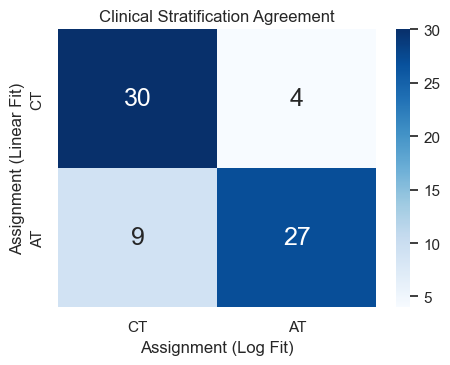

In [41]:
import seaborn as sns
from sklearn.metrics import cohen_kappa_score, confusion_matrix

# 2. CLINICAL AGREEMENT (Stratification)
bins = [-np.inf, 0.4, np.inf]
labels = ['CT', 'AT']

at_score_df['Strat_Linear'] = pd.cut(at_score_df['Linear Space'], bins=bins, labels=labels)
at_score_df['Strat_Log'] = pd.cut(at_score_df['Log Space'], bins=bins, labels=labels)

agreement_pct = (at_score_df['Strat_Linear'] == at_score_df['Strat_Log']).mean() * 100
kappa = cohen_kappa_score(at_score_df['Strat_Linear'], at_score_df['Strat_Log'])

print(f"Absolute Clinical Agreement: {agreement_pct:.1f}%")
print(f"Cohen's Kappa: {kappa:.2f}")

cm = confusion_matrix(at_score_df['Strat_Linear'], at_score_df['Strat_Log'], labels=labels)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Clinical Stratification Agreement")
plt.xlabel("Assignment (Log Fit)")
plt.ylabel("Assignment (Linear Fit)")
plt.tight_layout()
plt.show()